# Week 5 — Seoul Bike Sharing | Team B: Model Parameter Calibration

**Goal:** Calibrate `b0`, `b1`, `b2`, `b3` using hourly bike rentals, compare initial and calibrated forecasts on **identical unseen future hours**, and report MAE, RMSE and coefficient interpretations.

**Week 5 equation (slide 11):**

\[\widehat D(t+1) = b_0+b_1D(t)+b_2T(t+1)+b_3H(t+1)+g(\mathrm{hour}(t+1))\]

The hour-of-day effect `g` consists of 23 indicator coefficients (00:00 is the reference hour), as requested on slide 10. **The four primary coefficients are still `b0`–`b3`.** The same equation is used before and after calibration; only coefficients change.

**Relationship to Week 3 / Week 4:** The existing Week 3 multiplicative model and Week 4 state-synchronization model remain untouched in their notebooks. Because they do **not** contain `b0`–`b3`, this notebook is an explicitly separate **Week 5 linear calibration extension**, not a claim that the original Week 3 coefficients were calibrated. The slide's request to both retain that exact older equation *and* calibrate linear `b` coefficients is mathematically incompatible for our existing code. This implementation prioritizes the slide's explicit `b0–b3` equation and preserves the original notebooks.

**Forecasting assumptions:** At hour `t`, the observed rentals `D(t)` are available; historical measured weather at `t+1` is treated as a **perfect weather forecast**. `D(t+1)` is used only as the target, never as a feature. The evaluation is one-hour-ahead prediction (not free-running and not Week 4 `K=0.5` synchronization).

## 1. Load and validate hourly observations

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths = [Path('../SeoulBikeData.csv'), Path('SeoulBikeData.csv')]
csv_path = next((p for p in paths if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError('SeoulBikeData.csv should be in the repository root.')

df = pd.read_csv(csv_path, encoding='latin1')
df['Timestamp'] = (pd.to_datetime(df['Date'], dayfirst=True)
                   + pd.to_timedelta(df['Hour'], unit='h'))
columns = ['Timestamp', 'Rented Bike Count', 'Temperature(°C)',
           'Humidity(%)', 'Functioning Day']
print('Raw rows:', len(df))
print('Missing:', int(df[columns].isna().sum().sum()))
print('Duplicate timestamps:', int(df['Timestamp'].duplicated().sum()))

df = df[columns].dropna().drop_duplicates('Timestamp').copy()
df = df[(df['Rented Bike Count'] >= 0)
        & df['Humidity(%)'].between(0, 100)
        & df['Functioning Day'].isin(['Yes', 'No'])]
df = df.sort_values('Timestamp').reset_index(drop=True)
print('Valid rows:', len(df))
print('Period:', df.Timestamp.min(), 'to', df.Timestamp.max())

Raw rows: 8760
Missing: 0
Duplicate timestamps: 0
Valid rows: 8760
Period: 2017-12-01 00:00:00 to 2018-11-30 23:00:00


## 2. Build valid one-hour-ahead training examples

For each consecutive pair, the **current** rental count is a predictor, the **next-hour** temperature and humidity are assumed known forecasts, and the **next-hour** rental count is the target. We exclude pairs where the service was closed during either hour because observed zero rentals are not necessarily zero demand.

In [2]:
now = df.iloc[:-1].reset_index(drop=True)
nxt = df.iloc[1:].reset_index(drop=True)

pairs = pd.DataFrame({
    'Timestamp': nxt['Timestamp'],
    'D_current': now['Rented Bike Count'].to_numpy(),
    'T_next': nxt['Temperature(°C)'].to_numpy(),
    'H_next': nxt['Humidity(%)'].to_numpy(),
    'Hour_next': nxt['Timestamp'].dt.hour.to_numpy(),
    'D_next': nxt['Rented Bike Count'].to_numpy(),
})
consecutive = nxt['Timestamp'].sub(now['Timestamp']).eq(pd.Timedelta(hours=1))
operating = now['Functioning Day'].eq('Yes') & nxt['Functioning Day'].eq('Yes')
pairs = pairs.loc[consecutive & operating].reset_index(drop=True)
assert len(pairs) > 100
print('Valid one-hour-ahead examples:', len(pairs))
print(pairs.head().to_string(index=False))

Valid one-hour-ahead examples: 8452
          Timestamp  D_current  T_next  H_next  Hour_next  D_next
2017-12-01 01:00:00        254    -5.5      38          1     204
2017-12-01 02:00:00        204    -6.0      39          2     173
2017-12-01 03:00:00        173    -6.2      40          3     107
2017-12-01 04:00:00        107    -6.0      36          4      78
2017-12-01 05:00:00         78    -6.4      37          5     100


## 3. Chronological split: 70% train / 15% tune / 15% test

The rows are already sorted by their **target timestamp**. The last 15% are genuinely later than all training rows. There is **no shuffle**. We use the tune partition for diagnostics only; coefficients are fit on training data alone and then frozen.

In [3]:
n = len(pairs)
train_end = int(0.70 * n)
tune_end = int(0.85 * n)
train = pairs.iloc[:train_end].copy()
tune = pairs.iloc[train_end:tune_end].copy()
test = pairs.iloc[tune_end:].copy()
for label, part in [('Train', train), ('Tune', tune), ('Test', test)]:
    print(f'{label:5s}: {len(part):5d} hours | {part.Timestamp.min()} -> {part.Timestamp.max()}')
assert train.Timestamp.max() < tune.Timestamp.min() < test.Timestamp.min()

Train:  5916 hours | 2017-12-01 01:00:00 -> 2018-08-06 14:00:00
Tune :  1268 hours | 2018-08-06 15:00:00 -> 2018-10-03 14:00:00
Test :  1268 hours | 2018-10-03 15:00:00 -> 2018-11-30 23:00:00


## 4. Define the unchanged equation and original coefficients

**Before calibration:** `b0` = half of the *training* rental mean, `b1 = 0.5`, `b2 = b3 = 0`, hour corrections = 0. These are explicitly **initial guesses**, not the original Week 3 parameters. The pre-calibration predictions and fitted predictions use the **same formula**.

The hour dummy variables allow demand to differ by hour, without making the four coefficients change over time. Hour 00:00 is the reference category.

In [4]:
feature_names = ['b0', 'b1', 'b2', 'b3'] + [f'hour_{h:02d}' for h in range(1, 24)]

def design_matrix(data):
    x = np.column_stack([
        np.ones(len(data)),
        data['D_current'].to_numpy(dtype=float),
        data['T_next'].to_numpy(dtype=float),
        data['H_next'].to_numpy(dtype=float),
    ] + [(data['Hour_next'].to_numpy() == h).astype(float)
         for h in range(1, 24)])
    return x

def predict(data, coefficients):
    # Keep the *same equation* for original and calibrated coefficients.
    # Non-negative reporting: a bicycle rental count cannot be negative.
    return np.maximum(0.0, design_matrix(data) @ coefficients)

initial = np.zeros(len(feature_names))
initial[0] = 0.5 * train['D_next'].mean()
initial[1] = 0.5

print('Original coefficients (initial, not fitted):')
print(pd.Series(initial[:4], index=feature_names[:4]).to_string())

Original coefficients (initial, not fitted):
b0    324.090433
b1      0.500000
b2      0.000000
b3      0.000000


## 5. Calibrate `b0`–`b3` and hour effects by least squares (training only)

`np.linalg.lstsq` minimizes the **sum of squared errors**. Because the number of training rows is fixed, minimizing this sum also minimizes training RMSE. Test observations are not supplied to the fitting method. The resulting coefficients remain frozen for all later evaluations.

In [5]:
X_train = design_matrix(train)
y_train = train['D_next'].to_numpy(dtype=float)

calibrated, _, rank, _ = np.linalg.lstsq(X_train, y_train, rcond=None)
if rank != X_train.shape[1]:
    raise ValueError('The training design matrix does not have full rank.')

coefficient_table = pd.DataFrame({
    'Coefficient': ['b0: intercept', 'b1: persistence',
                    'b2: temperature (bikes/°C)', 'b3: humidity (bikes/%RH)'],
    'Original': initial[:4],
    'Calibrated': calibrated[:4],
})
print(coefficient_table.round(4).to_string(index=False))
print('Hour-effect coefficients fitted:', len(calibrated) - 4)

               Coefficient  Original  Calibrated
             b0: intercept  324.0904    -21.3227
           b1: persistence    0.5000      0.8692
b2: temperature (bikes/°C)    0.0000      4.3642
  b3: humidity (bikes/%RH)    0.0000     -1.0406
Hour-effect coefficients fitted: 23


## 6. Evaluate without retraining on tune/test

- **MAE:** average absolute error, bicycles/hour.
- **RMSE:** square-root of average squared error, bicycles/hour; large misses contribute more.
- **Persistence benchmark:** a third diagnostic predictor `D(t+1) = D(t)` to check whether the calibrated model also beats a simple, meaningful baseline. This is **not** part of calibration and does not change the required initial-vs-calibrated comparison.

In [6]:
def mae(y, forecast):
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(forecast))))

def rmse(y, forecast):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(forecast)) ** 2)))

scores = []
for name, part in [('Train', train), ('Tune', tune), ('Test', test)]:
    target = part['D_next'].to_numpy(dtype=float)
    candidates = {
        'Original b': predict(part, initial),
        'Calibrated b': predict(part, calibrated),
        'Persistence (diagnostic)': part['D_current'].to_numpy(dtype=float),
    }
    for model, forecast in candidates.items():
        scores.append({'Split': name, 'Model': model, 'Hours': len(part),
                       'MAE': mae(target, forecast), 'RMSE': rmse(target, forecast)})
metrics = pd.DataFrame(scores)
print(metrics.round(2).to_string(index=False))

original_mae = metrics.loc[(metrics.Split == 'Test') & (metrics.Model == 'Original b'), 'MAE'].iloc[0]
calibrated_mae = metrics.loc[(metrics.Split == 'Test') & (metrics.Model == 'Calibrated b'), 'MAE'].iloc[0]
print(f'\nTest MAE change (original minus calibrated): {original_mae-calibrated_mae:+.2f} bikes/hour')
print(f'Test MAE relative change: {(1-calibrated_mae/original_mae)*100:+.1f}%')
if calibrated_mae < original_mae:
    print('Calibration improved test MAE versus the initial coefficients.')
else:
    print('Calibration did NOT improve test MAE versus the initial coefficients.')

Split                    Model  Hours    MAE   RMSE
Train               Original b   5916 281.23 369.99
Train             Calibrated b   5916 125.97 188.57
Train Persistence (diagnostic)   5916 163.76 265.33
 Tune               Original b   1268 325.24 441.37
 Tune             Calibrated b   1268 162.57 225.07
 Tune Persistence (diagnostic)   1268 238.96 337.24
 Test               Original b   1268 270.63 369.51
 Test             Calibrated b   1268 131.43 194.81
 Test Persistence (diagnostic)   1268 214.89 313.91

Test MAE change (original minus calibrated): +139.20 bikes/hour
Test MAE relative change: +51.4%
Calibration improved test MAE versus the initial coefficients.


## 7. Comparison plot: exactly the same held-out test hours

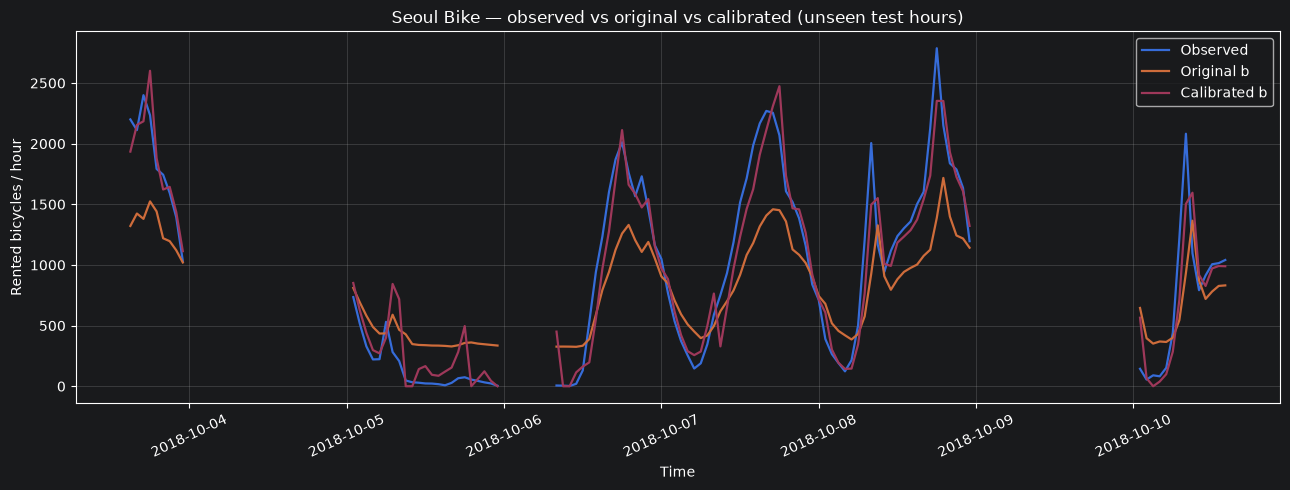

In [7]:
test_results = test[['Timestamp', 'D_next']].rename(columns={'D_next': 'Observed'}).copy()
test_results['Original b'] = predict(test, initial)
test_results['Calibrated b'] = predict(test, calibrated)

# First seven days of the unseen test partition; missing hours stay blank.
end_time = test_results.Timestamp.iloc[0] + pd.Timedelta(days=7)
chart = test_results[test_results.Timestamp < end_time].set_index('Timestamp').asfreq('h')
plt.figure(figsize=(13, 5))
for name in ['Observed', 'Original b', 'Calibrated b']:
    plt.plot(chart.index, chart[name], label=name, linewidth=1.6)
plt.title('Seoul Bike — observed vs original vs calibrated (unseen test hours)')
plt.xlabel('Time')
plt.ylabel('Rented bicycles / hour')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 8. Interpretation and Week 5 submission notes

**Interpretation:**

- `b0` is the intercept: baseline rentals when previous rentals, temperature and humidity are zero and the target hour is 00:00 (an algebraic reference, not an observed average).
- `b1` is dimensionless persistence: change in predicted next-hour rentals per +1 rental in the current hour, holding other inputs fixed.
- `b2` has units **bicycles per hour per °C**; its sign says whether an extra °C is associated with higher (+) or lower (−) expected rentals, conditional on other features.
- `b3` has units **bicycles per hour per percentage-point RH**; its sign has the analogous conditional interpretation for humidity.
- An association does **not** prove causality. Correlated predictors and seasonal changes may affect estimates.

**Requirement checklist:** original and fitted `b0`–`b3`; fit by training-only least squares; chronological 70/15/15; known predictors at forecast issue time (next weather assumed forecast); parameters frozen before unseen test; identical-hour test MAE and plot; explicit coefficient signs/units.

**Important limitation:** our actual Week 3 notebook uses a *different multiplicative equation* with month-hour averages and four weather effects. The linearly calibrated `b` model is an extension rather than a mathematical fit of those original multiplicative coefficients. Week 3 and Week 4 remain preserved, and Week 4's `K=0.5` is not tuned here. To satisfy a literal 'calibrate the exact original Week 3 equation' instead, the coefficients of the multiplicative effects would need fitting, which would not be the slide's linear `b0`–`b3` regression.

**Demo:** show the split, original-vs-fitted coefficient table, test MAE/RMSE, comparison plot, and interpretations of `b2`/`b3`.

In [8]:
for i, name in [(2, 'temperature'), (3, 'humidity')]:
    value = calibrated[i]
    direction = 'positive' if value > 0 else ('negative' if value < 0 else 'zero')
    print(f'{name.capitalize()} effect (b{i}): {value:+.3f} — {direction}')
print('Fitted coefficients remain fixed for all tune/test predictions.')

Temperature effect (b2): +4.364 — positive
Humidity effect (b3): -1.041 — negative
Fitted coefficients remain fixed for all tune/test predictions.
